# Forecasting pipeline: all regions → one JSON for the website

**What this does:** takes the cleaned data from the data team, and for **each region**:

1. turns it into one value per month,
2. flags unusual months (z-scores),
3. **tests** the forecast on the last 12 months against a simple benchmark,
4. forecasts the next 12 months with a 95% range,
5. writes everything to `forecasts.json` for Saaed.

**How to use it:**
- **Before the data arrives:** leave `DATA_FILE = None`. It runs on fake data for 6 regions so you can check everything works.
- **When the data arrives:** set `DATA_FILE` and the column names in the **Settings** cell, then *Kernel → Restart and Run All*.

The data team's file can have **any** date spacing (e.g. every 6–12 days from Sentinel-1); it gets turned into monthly values automatically.

## Settings: the only cell you should need to edit

In [1]:
DATA_FILE   = ["Brazil_Multi_Hazard_SAR_Flood_and_Forest_2019_2026.xlsx",   # one file, or a list of files (one per region)
               "Vietnam_Multi_Hazard_SAR_Flood_and_Forest_2019_2026.xlsx",  # None = practice with fake data
               "Italy_Multi_Hazard_SAR_Flood_Forest_Subsidence_2019_2026.xlsx",
               "London_Multi_Hazard_SAR_Flood_Forest_Subsidence_2019_2026_With_Coordinates.xlsx"]
SHEET       = "Flooding"      # only used for .xlsx files
REGION_COL  = "Study Area"    # column with the region ID
DATE_COL    = "Observation Date"
VALUE_COL   = "Potentially Flooded Area (km²)"     # the number to forecast
VALUE_ALIASES = ["Potentially Inundated Area (km²)", "potential_inundation_km2"]   # other names the same column has in some files
COLUMN_ALIASES = {"date": "Observation Date", "location": "Study Area",                 # London's file uses different names
                  "coverage_fraction": "Satellite Image Coverage (0–1)"}
REGION_RENAME = {"East London": "GBR_EAST_LONDON"}     # give every region an ID in the same style
COVERAGE_COL = "Satellite Image Coverage (0–1)"    # optional quality column; None if there isn't one
MIN_COVERAGE = 0.95           # drop scenes covering less of the study area than this
COORDS_SHEET = "Map Coordinates"                   # optional sheet with each study area's centre and bounds
LABEL = "Exploratory forecast of potential inundation indicator (km²)"   # wording requested in the data handover notes
NON_NEGATIVE = True           # areas and fractions can't go below 0, so clip forecast ranges at 0
MAX_FILLED_SHARE = 0.3        # warn if more than 30% of months had no observation and were filled in

AGGREGATE   = "mean"          # how to combine several readings in one month: "mean", "median" or "max"
HORIZON     = 12              # months to forecast
Z_FLAG      = 5               # |z| above this = flagged event (tune: check it catches known events, few false ones)
OUTPUT_FILE = "forecasts.json"

In [2]:
import json
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.exponential_smoothing.ets import ETSModel

warnings.filterwarnings("ignore")        # statsmodels prints lots of harmless warnings
plt.rcParams["figure.figsize"] = (10, 3.5)

## 1. Load the data

The pipeline expects a **long** table: one row per (region, date) reading. It can read **several files at once** (e.g. one workbook per region): list them in `DATA_FILE` and they are stacked into one table.

| region | date | water_km2 |
|---|---|---|
| Sindh | 2022-08-29 | 412.5 |
| Sindh | 2022-09-10 | 398.1 |
| Lake Mead | 2022-08-31 | 280.0 |

If the data team's file looks different, the easiest fix is to ask them for this shape, or adjust the column names in Settings.

In [3]:
def fake_data(seed=1):
    rng = np.random.default_rng(seed)
    dates = pd.date_range("2019-01-01", "2026-10-31", freq="12D")          # Sentinel-1-like revisits, from 2019 like the real data
    t = np.asarray((dates - dates[0]).days) / 365.25
    rows = []
    specs = {"Sindh, Pakistan": (300, 40, -2, ["2022-08", "2022-09"]),
             "Lake Mead, USA": (550, 15, -12, []),
             "Bangladesh delta": (900, 120, 3, ["2020-07", "2024-08"]),
             "Po Valley, Italy": (80, 10, 0, ["2023-05"]),
             "Dubai coast, UAE": (40, 1, -1.5, []),
             "Somerset Levels, UK": (25, 8, 0.2, ["2024-01"])}
    for name, (level, season, trend, floods) in specs.items():
        v = level + trend * t + season * np.cos(2 * np.pi * (t - 0.6)) + rng.normal(0, season * 0.15 + 1, len(t))
        for f in floods:
            v[dates.strftime("%Y-%m") == f] += level * 0.6
        rows.append(pd.DataFrame({REGION_COL: name, DATE_COL: dates, VALUE_COL: np.clip(v / 1600 * 100, 0, 100)}))
    return pd.concat(rows, ignore_index=True)

def read_one(path):
    df = pd.read_excel(path, sheet_name=SHEET) if str(path).endswith((".xlsx", ".xls")) else pd.read_csv(path)
    df = df.rename(columns={a: VALUE_COL for a in VALUE_ALIASES if a in df.columns})     # same column, one name
    df = df.rename(columns={k: v for k, v in COLUMN_ALIASES.items() if k in df.columns and v not in df.columns})
    df[REGION_COL] = df[REGION_COL].replace(REGION_RENAME)
    return df

locations = {}
if DATA_FILE is None:
    raw = fake_data()
    print("Using FAKE practice data")
else:
    files = DATA_FILE if isinstance(DATA_FILE, list) else [DATA_FILE]
    raw = pd.concat([read_one(p) for p in files], ignore_index=True)    # stack all regions into one table
    print("Loaded", len(files), "file(s)")
    if COVERAGE_COL and COVERAGE_COL in raw.columns:
        before = len(raw)
        raw = raw[raw[COVERAGE_COL] >= MIN_COVERAGE]
        print(f"Dropped {before - len(raw)} scenes with coverage below {MIN_COVERAGE:.0%}")

    # study-area locations for the map (centre + rectangle), if the workbooks include them
    locations = {}
    for path in files:
        if str(path).endswith((".xlsx", ".xls")) and COORDS_SHEET in pd.ExcelFile(path).sheet_names:
            c = pd.read_excel(path, sheet_name=COORDS_SHEET)
            needed = ["Study Area ID", "Centre Latitude", "Centre Longitude", "South Boundary", "West Boundary", "North Boundary", "East Boundary"]
            if not all(col in c.columns for col in needed):
                print(f"  (no study-area box in {path}; location left empty for that file)")
                continue
            c = c.dropna(subset=["Centre Latitude", "South Boundary"])
            for _, row in c.iterrows():
                locations[row["Study Area ID"]] = {
                    "country": row.get("Country"),
                    "centre": {"lat": float(row["Centre Latitude"]), "lon": float(row["Centre Longitude"])},
                    "bounds": {"south": float(row["South Boundary"]), "west": float(row["West Boundary"]),
                               "north": float(row["North Boundary"]), "east": float(row["East Boundary"])},
                    "note": "Study-area rectangle (WGS84); values are totals over this area, not a flood location"}
    print("Locations found for:", list(locations))

raw[DATE_COL] = pd.to_datetime(raw[DATE_COL])
raw = raw.dropna(subset=[VALUE_COL])
print(raw.shape, "rows |", raw[REGION_COL].nunique(), "regions")
print(raw.groupby(REGION_COL)[DATE_COL].agg(["min", "max", "count"]))

Loaded 4 file(s)
Dropped 443 scenes with coverage below 95%


  (no study-area box in London_Multi_Hazard_SAR_Flood_Forest_Subsidence_2019_2026_With_Coordinates.xlsx; location left empty for that file)
Locations found for: ['BRA_PORTO_VELHO', 'VNM_CAN_THO', 'VNM_BINH_PHUOC_FOREST', 'ITA_VENICE', 'ITA_BELLUNO_FOREST']
(1129, 31) rows | 4 regions
                       min        max  count
Study Area                                  
BRA_PORTO_VELHO 2019-01-11 2026-11-13    259
GBR_EAST_LONDON 2019-01-06 2026-11-14    154
ITA_VENICE      2019-01-01 2026-11-09    379
VNM_CAN_THO     2019-01-01 2026-11-03    337


## 2. One value per month, per region

`resample("MS")` groups readings into calendar months ("MS" = month start) and combines them with `AGGREGATE`. Months with no observation are filled by **interpolation** (a straight line between neighbours), and marked `"filled": true` in the JSON so the website can show them differently. If more than `MAX_FILLED_SHARE` of a region's months are filled in, you get a warning: the data is too sparse to trust a monthly forecast, so ask the data team for at least one acquisition per month.

In [4]:
def to_monthly(df_region):
    s = (df_region.set_index(DATE_COL)[VALUE_COL]
         .resample("MS").agg(AGGREGATE))
    filled = s.isna()
    s = s.interpolate(limit_area="inside")                 # fill gaps between real observations only
    keep = s.notna()
    return s[keep], filled[keep]

monthly, filled_months = {}, {}
for region, grp in raw.groupby(REGION_COL):
    s, filled = to_monthly(grp)
    monthly[region], filled_months[region] = s, filled
    share = filled.mean()
    warn = "  <-- WARNING: too sparse, ask for more acquisitions" if share > MAX_FILLED_SHARE else ""
    print(f"{region:22s} {len(s):4d} months ({s.index[0]:%Y-%m} to {s.index[-1]:%Y-%m}), {filled.sum()} filled in ({share:.0%}){warn}")

BRA_PORTO_VELHO          95 months (2019-01 to 2026-11), 2 filled in (2%)
GBR_EAST_LONDON          95 months (2019-01 to 2026-11), 39 filled in (41%)  <-- WARNING: too sparse, ask for more acquisitions
ITA_VENICE               95 months (2019-01 to 2026-11), 0 filled in (0%)
VNM_CAN_THO              95 months (2019-01 to 2026-11), 1 filled in (1%)


## 3. The model, the flags and the backtest

**Flags (z-scores):** compare each month with its **expected** value = trend (13-month rolling median) + that calendar month's typical deviation (e.g. the median of all Januaries). Divide by **that calendar month's own normal spread** (a robust standard deviation, MAD), because a flood season varies much more from year to year than a dry season. Medians everywhere, so the floods can't distort the baseline.

**Forecast range:** built from the model's **own past errors in each calendar month**, widening slowly the further ahead it looks. Flood-season months, where the model has been wrong by more in the past, get wider ranges than calm dry-season months. Robust = not dragged around by the floods themselves. Removing the seasons first matters: otherwise a normal wet winter hides a real flood, or a normal winter peak gets flagged.

**Forecast model (Holt-Winters / ETS):** smoothed level + damped trend + 12-month seasonal pattern. If a region has under 3 years of data, the seasonal part is dropped (not enough cycles to learn it).

**Backtest:** hide the last 12 months, forecast them, measure the average error (MAE), and compare with the **seasonal naive** benchmark ("same as last year"). **Skill** = 1 − MAE(model) / MAE(naive). Positive = model beats the benchmark; negative = it doesn't, and you should say so honestly.

Flagged months are replaced by their expected value before fitting, so one-off floods don't distort the forecast.

In [5]:
def robust_z(s):
    trend = s.rolling(13, center=True, min_periods=13).median()    # slow movement (a full 13-month median averages out the seasons)
    trend = trend.bfill().ffill()                                  # first/last 6 months: reuse the nearest full-window value
    if trend.isna().all():                                         # very short series: fall back to one overall median
        trend = pd.Series(s.median(), index=s.index)
    if len(s) >= 36:                                               # enough years: add each calendar month's typical deviation
        detrended = s - trend
        seasonal = detrended.groupby(detrended.index.month).transform("median")
        base = trend + seasonal
    else:
        base = trend
    resid = s - base
    mad_all = (resid - resid.median()).abs().median() * 1.4826
    mad_all = mad_all if mad_all > 0 else resid.std()
    if len(s) >= 36:
        # each calendar month gets its OWN normal spread: a flood season varies far more year to year than a dry season
        month_scale = resid.groupby(resid.index.month).transform(lambda r: (r - r.median()).abs().median() * 1.4826)
        scale = np.maximum(month_scale, mad_all)          # never smaller than the overall spread
    else:
        scale = pd.Series(mad_all, index=s.index)
    return resid / scale, base, scale

def fit_ets(y):
    seasonal = len(y) >= 36
    model = ETSModel(y, error="add", trend="add", damped_trend=True,
                     seasonal="add" if seasonal else None,
                     seasonal_periods=12 if seasonal else None)
    return model.fit(disp=False), seasonal

def run_region(s):
    z, base, scale = robust_z(s)
    flagged = z.abs() > Z_FLAG
    clean = s.where(~flagged, base)                       # replace flood months with the baseline

    # backtest on the last 12 months
    bt = None
    if len(clean) >= 36:
        train, test = clean[:-12], clean[-12:]
        fit_bt, _ = fit_ets(train)
        mae_model = float(np.mean(np.abs(test.values - fit_bt.forecast(12).values)))
        mae_naive = float(np.mean(np.abs(test.values - train[-12:].values)))
        bt = {"mae_model": round(mae_model, 3), "mae_seasonal_naive": round(mae_naive, 3),
              "skill": round(1 - mae_model / mae_naive, 3) if mae_naive > 0 else None}

    fit, seasonal = fit_ets(clean)
    pred = fit.get_prediction(start=len(clean), end=len(clean) + HORIZON - 1).summary_frame(alpha=0.05)
    # 95% range from the model's OWN past errors in each calendar month (robust spread of actual - fitted),
    # widening slowly the further ahead we forecast. ETS alone assumes errors are the same size all year,
    # which makes flood-season ranges too narrow and dry-season ranges too wide.
    if seasonal:
        err = s - fit.fittedvalues.reindex(s.index)
        err_sd = err.groupby(err.index.month).apply(lambda e: (e - e.median()).abs().median() * 1.4826)
        err_sd = np.maximum(err_sd, 0.25 * err_sd.median())               # avoid zero-width ranges
        steps = np.arange(1, HORIZON + 1)
        month_sd = pred.index.month.map(err_sd).to_numpy() * np.sqrt(1 + steps / 12)
        pred["pi_lower"], pred["pi_upper"] = pred["mean"] - 1.96 * month_sd, pred["mean"] + 1.96 * month_sd
    if NON_NEGATIVE:
        pred = pred.clip(lower=0)
    return {"z": z, "flagged": flagged, "pred": pred, "backtest": bt, "seasonal": seasonal}

results = {}
for region, s in monthly.items():
    results[region] = run_region(s)
    r = results[region]
    bt = r["backtest"]
    skill = "n/a (under 3 years of data)" if bt is None else f"{bt['skill']:+.2f}"
    print(f"{region:22s} flagged months: {int(r['flagged'].sum()):2d} | backtest skill vs naive: {skill}")

BRA_PORTO_VELHO        flagged months:  2 | backtest skill vs naive: +0.11


GBR_EAST_LONDON        flagged months:  4 | backtest skill vs naive: +0.16
ITA_VENICE             flagged months:  0 | backtest skill vs naive: +0.38


VNM_CAN_THO            flagged months:  5 | backtest skill vs naive: +0.23


## 4. Look at every region (always check by eye)

Things to check: do the red flags sit on real events? Does the forecast band look sensible (not exploding, not suspiciously narrow)?

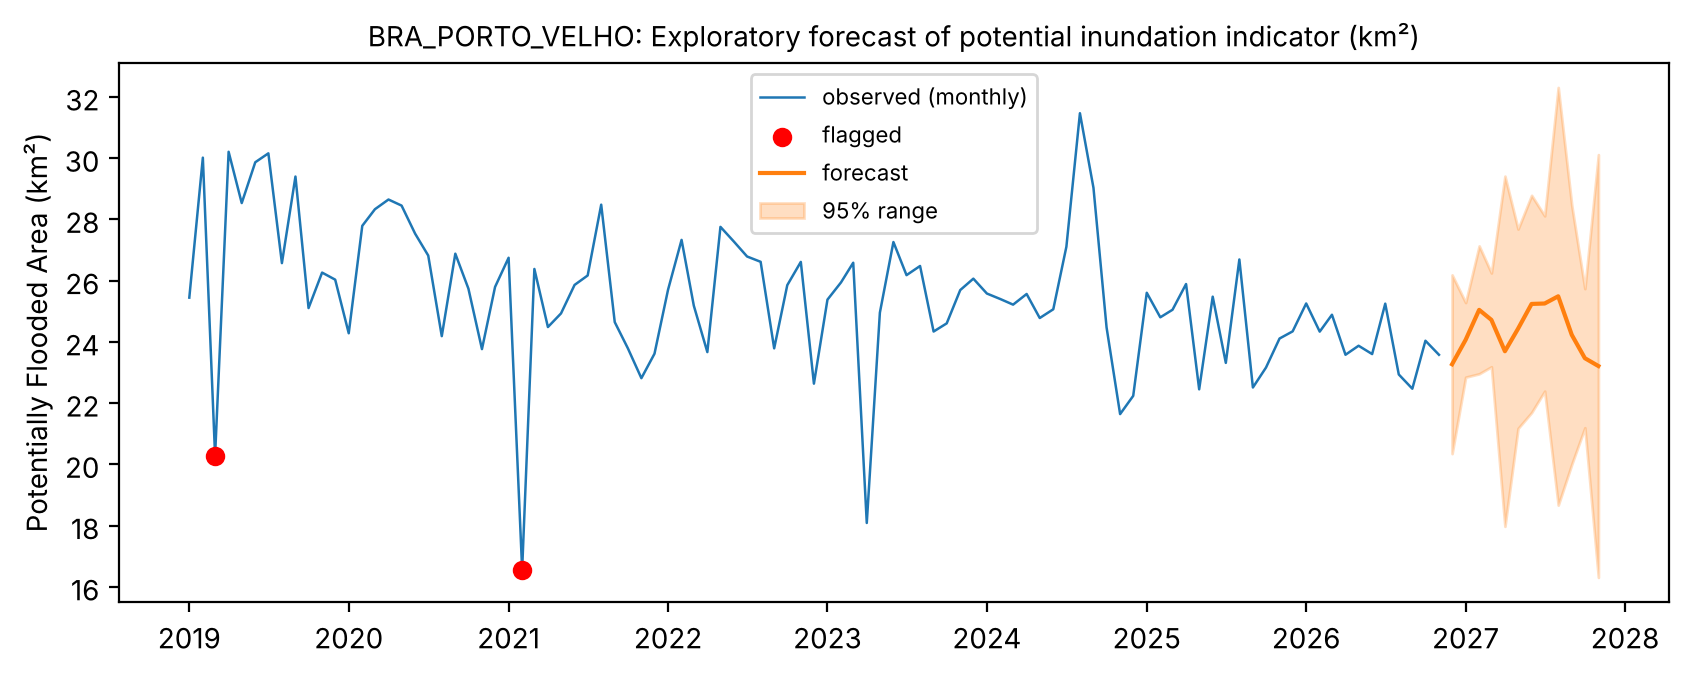

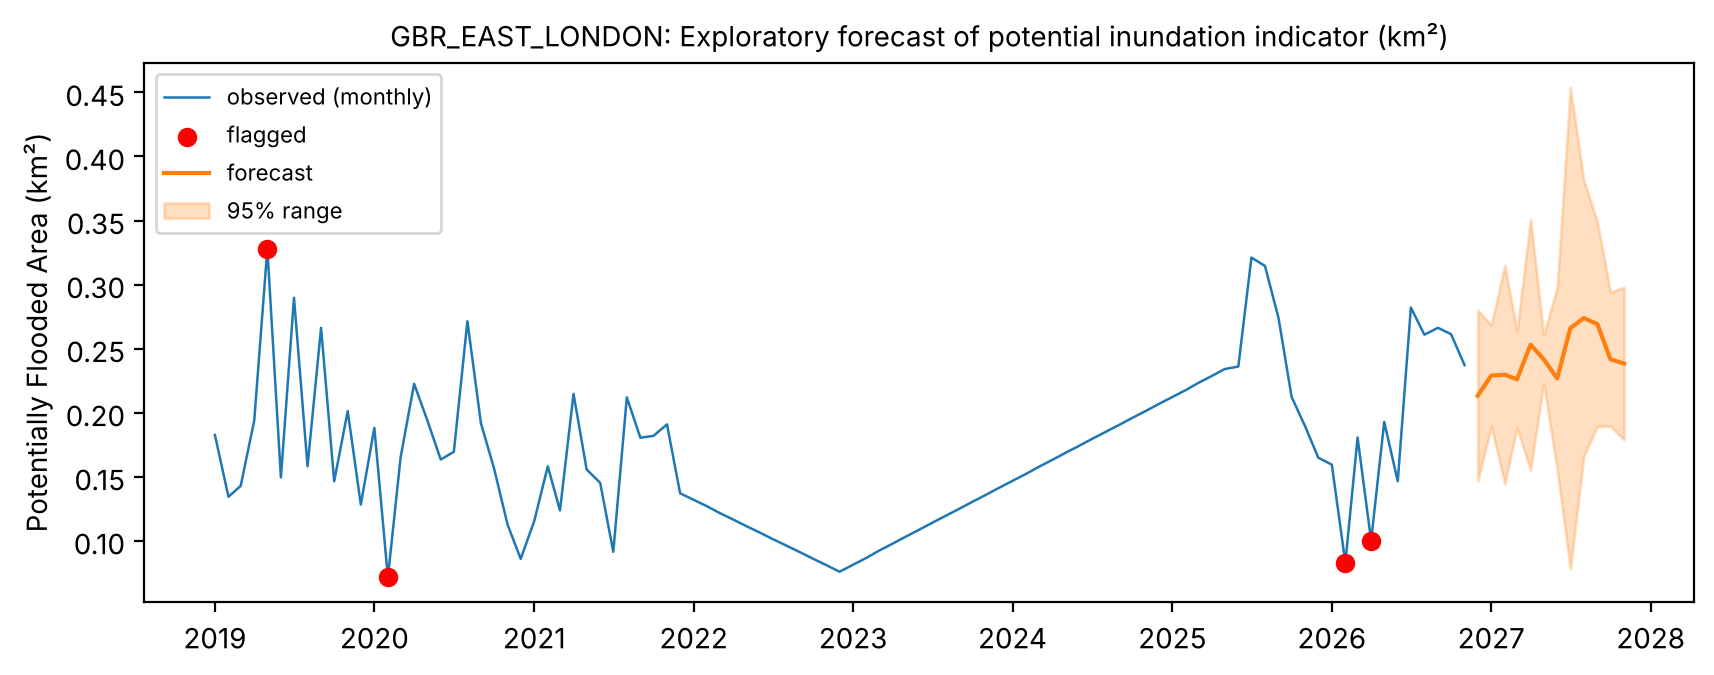

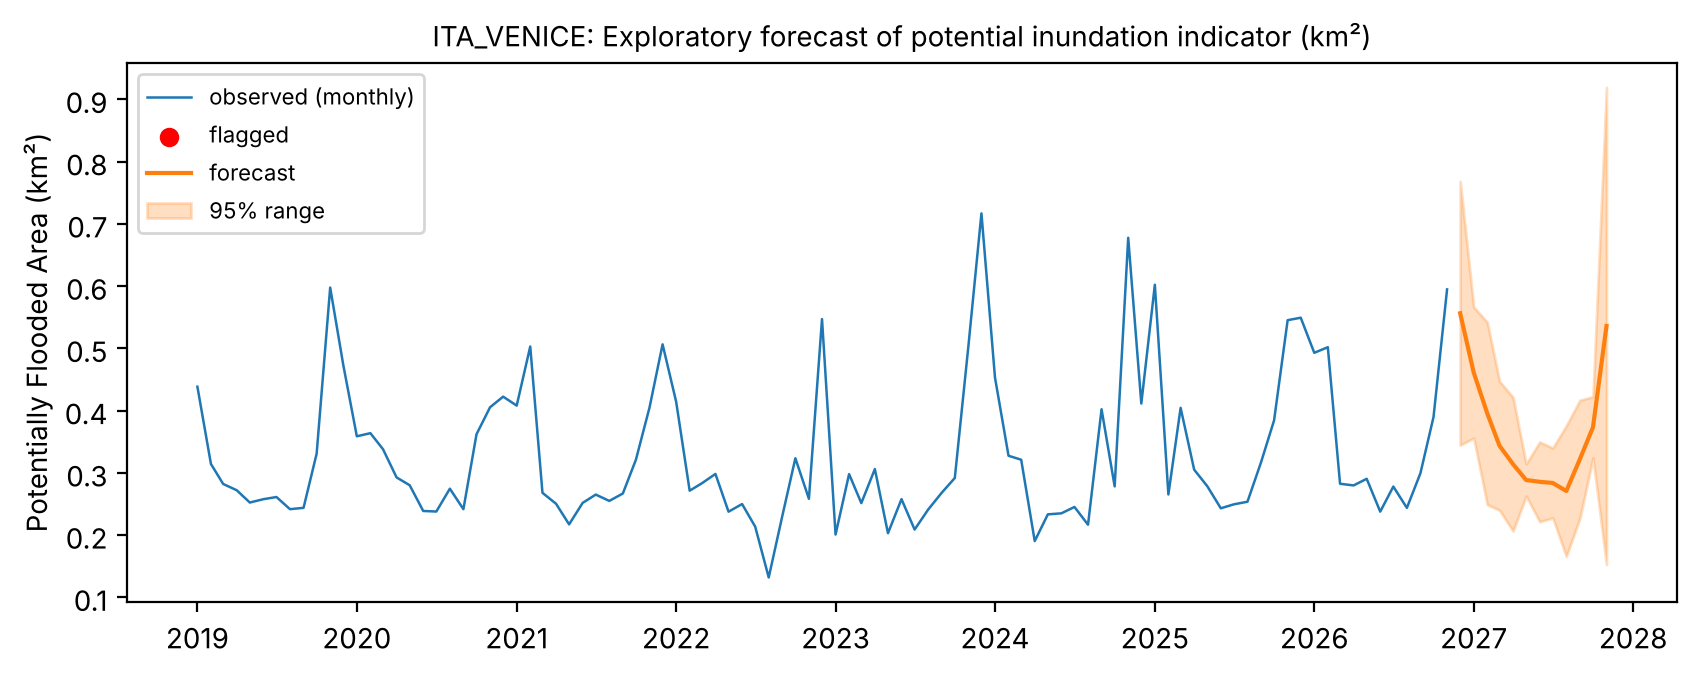

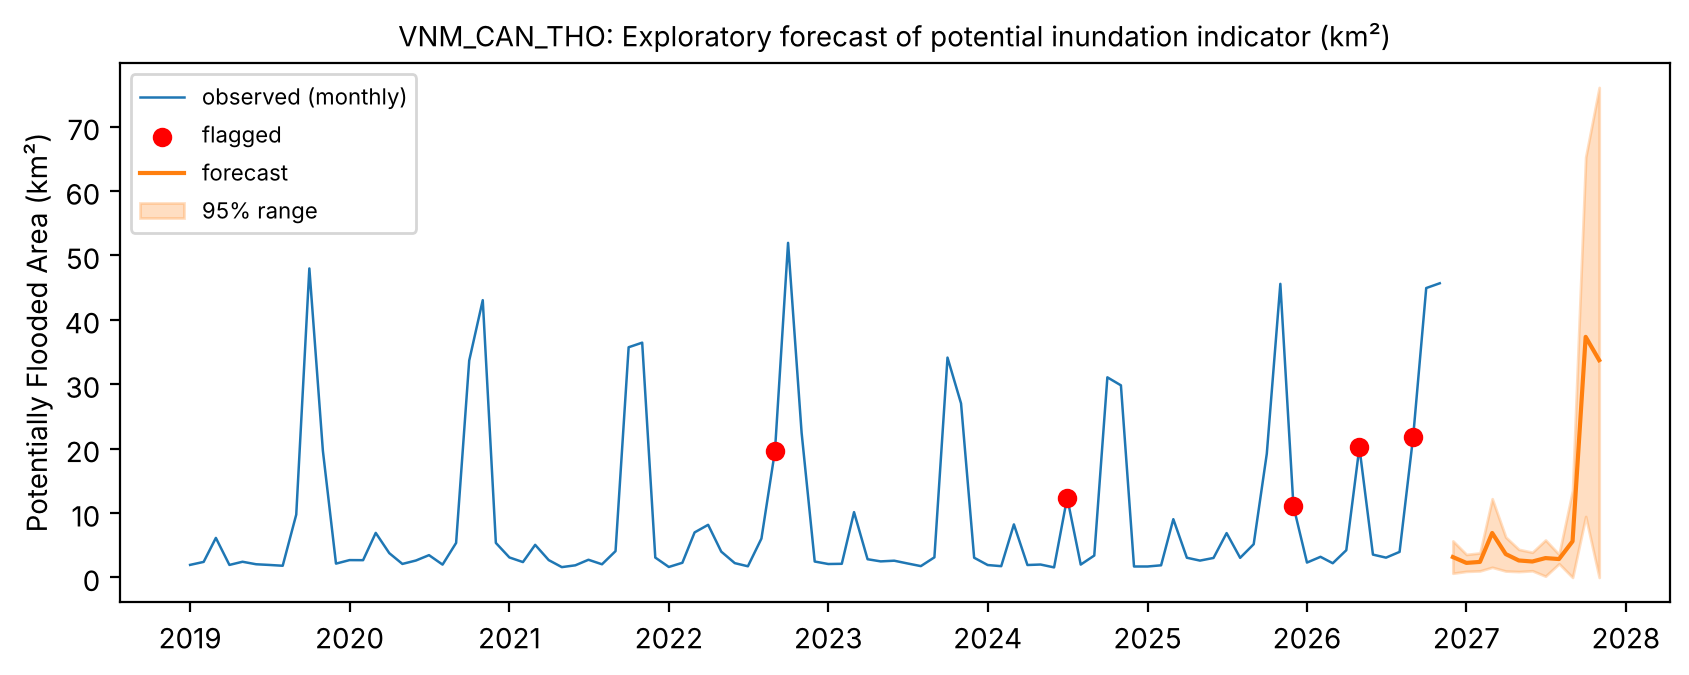

In [6]:
for region, s in monthly.items():
    r = results[region]
    plt.plot(s.index, s.values, lw=0.9, label="observed (monthly)")
    plt.scatter(s.index[r["flagged"]], s[r["flagged"]], c="r", zorder=3, label="flagged")
    plt.plot(r["pred"].index, r["pred"]["mean"], c="C1", label="forecast")
    plt.fill_between(r["pred"].index, r["pred"]["pi_lower"], r["pred"]["pi_upper"], color="C1", alpha=0.25, label="95% range")
    plt.title(f"{region}: {LABEL}", fontsize=10); plt.ylabel(VALUE_COL); plt.legend(fontsize=8, loc="best"); plt.show()

## 4b. Is each flood season getting bigger?

Take each year's **peak** month, then test whether peaks are rising or falling:

- **Theil-Sen slope:** the median of the slopes between every pair of years. Like a straight-line fit, but one extreme year can't drag it around (robust to outliers). Comes with a 95% confidence interval.
- **Kendall's tau test:** do later years tend to have bigger peaks? Gives a **p-value**: below 0.05 is the usual bar for "probably a real trend, not chance".

With only ~8 seasons, only a strong trend can pass this test. "No significant trend" means *we can't tell yet*, not *there is no trend*. The current year is left out if its data stops before the usual peak month (the season may not be over).

In [7]:
from scipy import stats

def peak_trend(s):
    peaks = s.groupby(s.index.year).max()
    peak_month = s.groupby(s.index.year).idxmax().dt.month
    typical_peak_month = int(peak_month.mode().iloc[0])
    last = s.index[-1]
    if last.month < 12 and last.month <= typical_peak_month:          # season possibly not finished
        peaks, peak_month = peaks.drop(last.year), peak_month.drop(last.year)
    years = peaks.index.to_numpy(dtype=float)
    if len(peaks) < 5:
        return peaks, peak_month, None
    slope, _, lo, hi = stats.theilslopes(peaks.values, years, 0.95)
    tau, p = stats.kendalltau(years, peaks.values)
    return peaks, peak_month, {"slope_per_year": round(float(slope), 3), "ci95": [round(float(lo), 3), round(float(hi), 3)],
                               "kendall_tau": round(float(tau), 3), "p_value": round(float(p), 3),
                               "significant": bool(p < 0.05), "n_seasons": int(len(peaks))}

peak_results = {}
for region, s in monthly.items():
    peaks, pmonth, tr = peak_trend(s)
    peak_results[region] = (peaks, pmonth, tr)
    print(f"\n{region}")
    print(pd.DataFrame({"peak": peaks.round(1), "month": pd.to_datetime(pmonth.astype(str), format="%m").dt.strftime("%b")}).T.to_string())
    if tr is None:
        print("  Too few seasons to test a trend.")
    else:
        verdict = "significant trend" if tr["significant"] else "no significant trend (can't tell yet)"
        print(f"  Peak trend: {tr['slope_per_year']:+.2f} per year, 95% CI {tr['ci95'][0]:+.2f} to {tr['ci95'][1]:+.2f}, p = {tr['p_value']:.2f} -> {verdict}")
    if pmonth.nunique() > 3:
        print("  Note: the peak month changes a lot between years, so these 'peaks' may not be one consistent flood season.")


BRA_PORTO_VELHO
Observation Date  2019  2020  2021  2022  2023  2024  2025  2026
peak              30.2  28.6  28.5  27.8  27.3  31.5  26.7  25.3
month              Apr   Apr   Aug   May   Jun   Aug   Aug   Jan
  Peak trend: -0.58 per year, 95% CI -0.82 to -0.17, p = 0.03 -> significant trend
  Note: the peak month changes a lot between years, so these 'peaks' may not be one consistent flood season.

GBR_EAST_LONDON
Observation Date 2019 2020 2021 2022 2023 2024 2025 2026
peak              0.3  0.3  0.2  0.1  0.1  0.2  0.3  0.3
month             May  Aug  Apr  Jan  Dec  Dec  Jul  Jul
  Peak trend: -0.00 per year, 95% CI -0.06 to +0.04, p = 0.91 -> no significant trend (can't tell yet)
  Note: the peak month changes a lot between years, so these 'peaks' may not be one consistent flood season.

ITA_VENICE
Observation Date 2019 2020 2021 2022 2023 2024 2025
peak              0.6  0.4  0.5  0.5  0.7  0.7  0.6
month             Nov  Dec  Dec  Dec  Dec  Nov  Jan
  Peak trend: +0.03 per year

## 5. Write the JSON for the website

Agree this shape with Saaed. Each region has:
- `location`: study-area centre and rectangle (lat/lon), from the workbook's Map Coordinates sheet,
- `history`: month + value + z-score + flagged + filled (filled = no satellite pass that month, value interpolated),
- `forecast`: month + mean + lower + upper (the 95% band),
- `events`: just the flagged months (map markers; also what the AI layer explains),
- `backtest`: the honesty check, worth showing in the demo,
- `seasonal_peaks` and `peak_trend`: each year's peak, and whether peaks are rising (slope, 95% CI, p-value).

In [8]:
def r3(x): return None if pd.isna(x) else round(float(x), 3)

out = {"label": LABEL, "metric": VALUE_COL, "generated": pd.Timestamp.now().strftime("%Y-%m-%d %H:%M"),
       "caveat": "Radar-derived indicator, not validated flood extent, damage or risk to people. Ranges are 95% prediction intervals.",
       "regions": {}}
for region, s in monthly.items():
    r = results[region]
    out["regions"][region] = {
        "location": locations.get(region),
        "history": [{"month": f"{m:%Y-%m}", "value": r3(v), "z": r3(zv), "flagged": bool(f), "filled": bool(fi)}
                    for m, v, zv, f, fi in zip(s.index, s.values, r["z"].values, r["flagged"].values,
                                               filled_months[region].values)],
        "forecast": [{"month": f"{m:%Y-%m}", "mean": r3(row["mean"]), "lower": r3(row["pi_lower"]), "upper": r3(row["pi_upper"])}
                     for m, row in r["pred"].iterrows()],
        "events": [{"month": f"{m:%Y-%m}", "value": r3(s[m]), "z": r3(r["z"][m]),
                    "direction": "above normal" if r["z"][m] > 0 else "below normal"}
                   for m in s.index[r["flagged"]]],
        "backtest": r["backtest"],
        "seasonal_peaks": [{"year": int(y), "peak": r3(v), "month": int(m)}
                           for (y, v), m in zip(peak_results[region][0].items(), peak_results[region][1].values)],
        "peak_trend": peak_results[region][2],
        "model": "ETS (Holt-Winters), damped trend" + (", 12-month seasonality" if r["seasonal"] else ", no seasonality"),
    }

with open(OUTPUT_FILE, "w") as f:
    json.dump(out, f, indent=1)
print(f"Wrote {OUTPUT_FILE}")
first = next(iter(out["regions"]))
print(json.dumps({first: {k: (v[:2] if isinstance(v, list) else v) for k, v in out["regions"][first].items()}}, indent=1))

Wrote forecasts.json
{
 "BRA_PORTO_VELHO": {
  "location": {
   "country": "Brazil",
   "centre": {
    "lat": -8.8,
    "lon": -63.925
   },
   "bounds": {
    "south": -8.95,
    "west": -64.1,
    "north": -8.65,
    "east": -63.75
   },
   "note": "Study-area rectangle (WGS84); values are totals over this area, not a flood location"
  },
  "history": [
   {
    "month": "2019-01",
    "value": 25.445,
    "z": -0.892,
    "flagged": false,
    "filled": false
   },
   {
    "month": "2019-02",
    "value": 30.017,
    "z": 2.619,
    "flagged": false,
    "filled": false
   }
  ],
  "forecast": [
   {
    "month": "2026-12",
    "mean": 23.269,
    "lower": 20.351,
    "upper": 26.187
   },
   {
    "month": "2027-01",
    "mean": 24.065,
    "lower": 22.847,
    "upper": 25.283
   }
  ],
  "events": [
   {
    "month": "2019-03",
    "value": 20.275,
    "z": -5.277,
    "direction": "below normal"
   },
   {
    "month": "2021-02",
    "value": 16.555,
    "z": -7.35,
    "direct

## 6. Tomorrow: risk severity index (draft idea to discuss with your lead)

A 1–10 score per flagged event, built from things the data actually measures, so it's explainable to judges:

| Component | Measures | Example scaling to 0–1 |
|---|---|---|
| **Magnitude** | how unusual: \|z\| | min(\|z\| / 8, 1) |
| **Extent** | how big relative to normal: value ÷ baseline − 1 | min(excess / 1.0, 1) |
| **Duration** | how many consecutive months flagged | min(months / 3, 1) |

$$\text{severity} = 1 + 9 \times (0.5\,\text{magnitude} + 0.3\,\text{extent} + 0.2\,\text{duration})$$

The weights are a **judgement call**: say so in the pitch, and show the score ranks known events sensibly (e.g. Pakistan 2022 should score near 10).